# 02 — The map and the headline shift · One Dial or Many?

Part 1 (**how many dials?**) and Part 2a (**where does the strict instruction push the model?**) from `approach.md`. Forward passes only — no generation.

| § | What | Output |
| --- | --- | --- |
| 0–2 | Setup; load splits + selected direction from 01 | — |
| 3 | Cache activations at two positions (`<end_of_turn>` = where the causal direction lives, and the final token) for toxic-fit, Alpaca-fit, Hard-1K-fit × none/neutral/strict, XSTest-safe × none/neutral/strict | `acts/*/chunk_*.pt` (resumable) |
| 4 | Massive-dimension masks (raw / small / large) | — |
| 5 | **Direction A** at every layer + split-half reliability; check it reproduces 01's causal direction | fig 1 |
| 6 | **Category directions**: cosine matrix (raw and with A removed), noise-corrected; **PCA** with a "one dial + noise" null | figs 2–3 |
| 7 | **Headline:** cos(strict − neutral shift, Direction A) per layer, with bootstrap CI, noise ceiling and sign-flip floor; "exchange rate" | fig 4 |
| 8 | Does the strict prompt push each Hard-1K category toward **its own** category dial? | fig 5 |
| 9 | Refusal-axis projections (caution-map preview) | fig 6 |
| 10 | Sensitivity to the massive-dim mask; summary JSON for the report and the page | `reports/results_02.json` |

**Inputs:** 01's `data/` folder (splits, `instructions.json`, `refusal_direction.pt`, `massive_dims.json`). If this is a new Kaggle session, attach 01's saved output (*Add Input → Notebook Output*) or the uploaded zip; §2 copies it over automatically.

**Conventions.** All geometry uses **masked** vectors (massive dims zeroed — see 01: they hold ≈ 87% of the raw harmful − harmless difference and are not refusal). Sign conventions: harmful − harmless, strict − neutral. Main position = `<end_of_turn>`; main layer = the causal layer selected in 01.

## 0 · Environment, storage, login

In [45]:
import importlib, subprocess, sys
from importlib.metadata import version, PackageNotFoundError

def need(pkg, mm):
    try:
        return tuple(int(x) for x in version(pkg).split(".")[:2]) < mm
    except PackageNotFoundError:
        return True

to_install = [s for p, mm, s in [("transformers", (4, 50), "transformers>=4.50"),
                                 ("accelerate", (0, 26), "accelerate>=0.26"),
                                 ("datasets", (2, 14), "datasets>=2.14")] if need(p, mm)]
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    print("Installed:", to_install, "-> RESTART THE KERNEL, then run from the next cell.")
else:
    print({p: version(p) for p in ["transformers", "accelerate", "datasets", "torch"]})

{'transformers': '5.20.2', 'accelerate': '1.15.0', 'datasets': '4.8.5', 'torch': '2.11.0+cu130'}


In [46]:
import os, sys, json, time, math, random, glob, shutil
from contextlib import nullcontext
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

IN_KAGGLE = os.path.exists("/kaggle")
IN_COLAB = (not IN_KAGGLE) and ("google.colab" in sys.modules or os.path.exists("/content"))
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/IE624"
elif IN_KAGGLE:
    ROOT = "/kaggle/working/IE624"
else:
    ROOT = os.path.abspath("IE624_runs")

DATA = f"{ROOT}/data"
RUN = f"{ROOT}/runs/02_map_and_shift"
for d in [DATA, f"{RUN}/acts", f"{RUN}/reports", f"{RUN}/page"]:
    os.makedirs(d, exist_ok=True)
print("Platform:", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local", "| ROOT:", ROOT)

token = None
try:
    if IN_COLAB:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    elif IN_KAGGLE:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception as e:
    print("Could not read HF_TOKEN from secrets:", e)
token = token or os.environ.get("HF_TOKEN")
assert token, "Add HF_TOKEN to the notebook secrets."
from huggingface_hub import login
login(token=token)

Platform: Kaggle | ROOT: /kaggle/working/IE624


In [47]:
import numpy as np, pandas as pd, torch
import torch.nn.functional as F

def save_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=str)
    os.replace(tmp, path)

def load_json(path, default=None):
    if not os.path.exists(path):
        return default
    with open(path) as f:
        return json.load(f)

def torch_save_atomic(obj, path):
    torch.save(obj, path + ".tmp")
    os.replace(path + ".tmp", path)

CHECKS_PATH = f"{RUN}/reports/checks.json"
CHECKS = load_json(CHECKS_PATH, default={})

def record(name, ok, **info):
    CHECKS[name] = {"ok": bool(ok), "time": time.strftime("%Y-%m-%d %H:%M:%S"), **info}
    save_json(CHECKS, CHECKS_PATH)
    print(("PASS " if ok else "FAIL ") + name, json.dumps(info, default=str)[:600])

# Results for the report / page accumulate here and are saved after every section.
RES_PATH = f"{RUN}/reports/results_02.json"
RES = load_json(RES_PATH, default={})

def save_res(**kv):
    RES.update(kv)
    save_json(RES, RES_PATH)

def to_list(t, nd=4):
    return np.round(t.detach().cpu().numpy().astype(float), nd).tolist()

random.seed(0); np.random.seed(0); torch.manual_seed(0)

## 1 · Inputs from notebook 01

In [48]:
REQUIRED = ["orbench_toxic.parquet", "orbench_hard1k.parquet", "alpaca.parquet", "instructions.json",
            "refusal_direction.pt", "massive_dims.json"]
missing = [f for f in REQUIRED if not os.path.exists(f"{DATA}/{f}")]
if missing and IN_KAGGLE:
    for src in glob.glob("/kaggle/input/**/IE624/data", recursive=True):
        for f in os.listdir(src):
            if not os.path.exists(f"{DATA}/{f}"):
                shutil.copy(os.path.join(src, f), DATA); print("copied", f, "from", src)
    missing = [f for f in REQUIRED if not os.path.exists(f"{DATA}/{f}")]
assert not missing, (f"Missing {missing}. Run 01 in this session, or attach 01's saved output / the zip "
                     "as a Kaggle input (Add Input) and re-run this cell.")

tox = pd.read_parquet(f"{DATA}/orbench_toxic.parquet")
hard = pd.read_parquet(f"{DATA}/orbench_hard1k.parquet")
alp = pd.read_parquet(f"{DATA}/alpaca.parquet")
xst = pd.read_parquet(f"{DATA}/xstest.parquet") if os.path.exists(f"{DATA}/xstest.parquet") else None
INSTRUCTIONS = load_json(f"{DATA}/instructions.json")
POLICY = load_json(f"{DATA}/category_policy.json", default={"exclude_from_category_analysis": ["harmful"]})
EXCLUDE = POLICY["exclude_from_category_analysis"]
SEL = torch.load(f"{DATA}/refusal_direction.pt")
MASSIVE_LARGE = load_json(f"{DATA}/massive_dims.json")["massive_dims"]
L_STAR = int(SEL["layer"])
print(f"Selected causal direction: layer {L_STAR}, pos {SEL['pos']}, variant {SEL['variant']}, "
      f"KL {SEL['kl']:.3f}, bypass {SEL['bypass']:.1f}, induce {SEL['induce']:.1f}")
print({k: len(v) for k, v in {"toxic": tox, "hard": hard, "alpaca": alp}.items()}, "| exclude:", EXCLUDE)

Selected causal direction: layer 17, pos -5, variant mask, KL 0.018, bypass -47.8, induce 5.9
{'toxic': 655, 'hard': 1319, 'alpaca': 600} | exclude: ['harmful']


## 2 · Model (fp32 across 2× T4; bf16 on L4/A100)

In [ ]:
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
assert torch.cuda.is_available(), "No GPU attached."
mems = [torch.cuda.get_device_properties(i).total_memory / 2**30 for i in range(torch.cuda.device_count())]
native_bf16 = all(torch.cuda.get_device_capability(i)[0] >= 8 for i in range(len(mems)))
DTYPE = torch.bfloat16 if native_bf16 else torch.float32 if sum(mems) >= 24 else torch.bfloat16

MODEL_ID = "google/gemma-3-4b-it"
BATCH = 16
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
DTYPE_KW = "dtype" if int(transformers.__version__.split(".")[0]) >= 5 else "torch_dtype"
load_kw = {DTYPE_KW: DTYPE, "device_map": "auto", "low_cpu_mem_usage": True}
try:
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, **load_kw)
except Exception as e:
    print("AutoModelForCausalLM failed:", e)
    from transformers import Gemma3ForConditionalGeneration
    model = Gemma3ForConditionalGeneration.from_pretrained(MODEL_ID, **load_kw)
model.eval(); torch.set_grad_enabled(False)
print("loaded as", next(model.parameters()).dtype)

In [49]:
# Helpers that depend on the loaded model (separate cell: re-run this alone if anything below says NameError).
N_LAYERS = len([m for n_, m in model.named_modules() if isinstance(m, torch.nn.ModuleList)
                and n_.endswith("layers") and "vision" not in n_][-1])
D_MODEL = getattr(model.config, "text_config", model.config).hidden_size
INPUT_DEVICE = model.get_input_embeddings().weight.device
record("model_load", True, n_layers=N_LAYERS, d_model=D_MODEL, dtype=str(next(model.parameters()).dtype))

def fmt(question, instruction=None):
    content = f"{instruction}\n\n{question}" if instruction else question
    return tok.apply_chat_template([{"role": "user", "content": content}], tokenize=False, add_generation_prompt=True)

def encode(texts):
    return tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(INPUT_DEVICE)

EOT_ID = tok.convert_tokens_to_ids("<end_of_turn>")
REFUSAL_IDS = sorted({tok(s, add_special_tokens=False)["input_ids"][0] for s in ["I", "Sorry"]})
_NONREF = None

def refusal_score(logits):
    global _NONREF
    lp = torch.log_softmax(logits.float(), -1)
    if _NONREF is None or _NONREF.numel() != lp.shape[-1]:
        _NONREF = torch.ones(lp.shape[-1], dtype=torch.bool); _NONREF[REFUSAL_IDS] = False
    return torch.logsumexp(lp[:, REFUSAL_IDS], -1) - torch.logsumexp(lp[:, _NONREF], -1)

PASS model_load {"n_layers": 34, "d_model": 2560, "dtype": "torch.float32"}


## 3 · Cache activations at two positions (resumable)

For each prompt: the residual stream entering every layer at `<end_of_turn>` (position −5, where the causal direction was selected) and at the final token (−1), plus the fast refusal score. One file per 128 prompts; finished chunks are skipped. \~3,300 prompts, \~5 minutes.

In [50]:
POSITIONS = {"eot": 0, "last": 1}   # index into the stored position axis
OFFSETS = [-5, -1]

assert RUN.endswith("02_map_and_shift"), (f"RUN = {RUN} — you are in another notebook's kernel state. "
                                          "Re-run the §0 environment and helper cells of THIS notebook first.")

@torch.no_grad()
def cache_run(name, df, instruction_name="none", chunk_size=128):
    out_dir = f"{RUN}/acts/{name}"; os.makedirs(out_dir, exist_ok=True)
    old = load_json(f"{out_dir}/manifest.json")
    if old is not None and old.get("offsets") != OFFSETS:
        raise RuntimeError(f"{out_dir} holds activations in a different format ({old}); delete it or fix RUN.")
    save_json({"instruction_name": instruction_name, "n": len(df), "offsets": OFFSETS}, f"{out_dir}/manifest.json")
    instr = INSTRUCTIONS[instruction_name]
    prompts, idl = [fmt(q, instr) for q in df["prompt"]], df["id"].tolist()
    n_chunks = math.ceil(len(prompts) / chunk_size)
    for c in range(n_chunks):
        path = f"{out_dir}/chunk_{c:04d}.pt"
        if os.path.exists(path):
            continue
        s, e = c * chunk_size, min((c + 1) * chunk_size, len(prompts))
        H, S = [], []
        for b in range(s, e, BATCH):
            enc = encode(prompts[b:min(b + BATCH, e)])
            T = enc["input_ids"].shape[1]
            assert bool((enc["input_ids"][:, T - 5] == EOT_ID).all()), "position -5 is not <end_of_turn>"
            try:
                out = model(**enc, output_hidden_states=True, logits_to_keep=1)
            except TypeError:
                out = model(**enc, output_hidden_states=True)
            H.append(torch.stack([h[:, [T - 5, T - 1], :].float().cpu() for h in out.hidden_states[:-1]], dim=1))
            S.append(refusal_score(out.logits[:, -1, :].float().cpu()))
        torch_save_atomic({"ids": idl[s:e], "acts": torch.cat(H), "refusal_score": torch.cat(S)}, path)
        print(f"  {name}: chunk {c + 1}/{n_chunks}")
    files = sorted(glob.glob(f"{out_dir}/chunk_*.pt"))
    parts = [torch.load(f) for f in files]
    run = {"ids": sum((p["ids"] for p in parts), []), "acts": torch.cat([p["acts"] for p in parts]),
           "refusal_score": torch.cat([p["refusal_score"] for p in parts])}
    assert run["ids"] == idl, f"{name}: cached ids do not match the dataframe order"
    assert run["acts"].dim() == 4 and run["acts"].shape[2] == len(OFFSETS), \
        f"{name}: activations have shape {tuple(run['acts'].shape)}, expected [n, L, {len(OFFSETS)}, d]"
    return run

tox_fit = tox[tox.split == "fit"].reset_index(drop=True)
alp_fit = alp[alp.split == "fit"].reset_index(drop=True)
hard_fit = hard[hard.split == "fit"].reset_index(drop=True)
t0 = time.time()
R = {"tox_none": cache_run("tox_fit_none", tox_fit), "alp_none": cache_run("alp_fit_none", alp_fit)}
for c in ("none", "neutral", "strict"):
    R[f"hard_{c}"] = cache_run(f"hard_fit_{c}", hard_fit, c)
if xst is not None:
    lab = "label" if "label" in xst.columns else "type"
    xst_safe = xst[(xst[lab].astype(str) == "safe")].reset_index(drop=True)
    for c in ("none", "neutral", "strict"):
        R[f"xst_{c}"] = cache_run(f"xst_safe_{c}", xst_safe, c)
record("cache", True, minutes=round((time.time() - t0) / 60, 1), sets={k: len(v["ids"]) for k, v in R.items()})

  tox_fit_none: chunk 1/3
  tox_fit_none: chunk 2/3
  tox_fit_none: chunk 3/3
  alp_fit_none: chunk 1/3
  alp_fit_none: chunk 2/3
  alp_fit_none: chunk 3/3
  hard_fit_none: chunk 1/6
  hard_fit_none: chunk 2/6
  hard_fit_none: chunk 3/6
  hard_fit_none: chunk 4/6
  hard_fit_none: chunk 5/6
  hard_fit_none: chunk 6/6
  hard_fit_neutral: chunk 1/6
  hard_fit_neutral: chunk 2/6
  hard_fit_neutral: chunk 3/6
  hard_fit_neutral: chunk 4/6
  hard_fit_neutral: chunk 5/6
  hard_fit_neutral: chunk 6/6
  hard_fit_strict: chunk 1/6
  hard_fit_strict: chunk 2/6
  hard_fit_strict: chunk 3/6
  hard_fit_strict: chunk 4/6
  hard_fit_strict: chunk 5/6
  hard_fit_strict: chunk 6/6
  xst_safe_none: chunk 1/2
  xst_safe_none: chunk 2/2
  xst_safe_neutral: chunk 1/2
  xst_safe_neutral: chunk 2/2
  xst_safe_strict: chunk 1/2
  xst_safe_strict: chunk 2/2
PASS cache {"minutes": 8.4, "sets": {"tox_none": 325, "alp_none": 300, "hard_none": 657, "hard_neutral": 657, "hard_strict": 657, "xst_none": 250, "xst_neut

## 4 · Masks for the massive dimensions

- **large** — the 46 dims from 01 (top-5 by magnitude at any layer/position); the causal direction was selected with this mask, so it is the **main** mask.
- **small** — top-5 at any layer, final position only (≈ 15 dims), for sensitivity.
- **raw** — no mask, to show what goes wrong without it.

In [51]:
mean_abs = 0.5 * (R["tox_none"]["acts"].abs().mean(0) + R["alp_none"]["acts"].abs().mean(0))  # [L, 2, d]
MASSIVE_SMALL = sorted({int(d) for l in range(1, N_LAYERS) for d in torch.topk(mean_abs[l, 1], 5).indices})
MASKS = {"raw": [], "small": MASSIVE_SMALL, "large": MASSIVE_LARGE}
MAIN = "large"
print({k: len(v) for k, v in MASKS.items()}, "| small:", MASSIVE_SMALL)

def masked(v, mask=MAIN):
    if not MASKS[mask]:
        return v
    v = v.clone(); v[..., MASKS[mask]] = 0
    return v

def unit(v):
    return v / v.norm(dim=-1, keepdim=True).clamp_min(1e-12)

def cosv(a, b):
    return (unit(a) * unit(b)).sum(-1)

def wmean(X, W):
    """Weighted means of X [n, ...] for each row of W [B, n] -> [B, ...]."""
    return (W @ X.reshape(X.shape[0], -1)).reshape(W.shape[0], *X.shape[1:])

def boot_W(n, B, g):
    idx = torch.randint(0, n, (B, n), generator=g)
    return torch.zeros(B, n).scatter_add_(1, idx, torch.ones(B, n)) / n

def half_W(n, B, g):
    perm = torch.argsort(torch.rand(B, n, generator=g), dim=1)
    h = n // 2
    W1 = torch.zeros(B, n).scatter_(1, perm[:, :h], 1.0) / h
    W2 = torch.zeros(B, n).scatter_(1, perm[:, h:], 1.0) / (n - h)
    return W1, W2

def spearman_brown(r):
    r = r.clamp(-0.999, 0.999)
    return 2 * r / (1 + r)

save_res(masks={k: v for k, v in MASKS.items()}, main_mask=MAIN, L_star=L_STAR)

{'raw': 0, 'small': 15, 'large': 46} | small: [19, 236, 295, 368, 435, 443, 634, 1055, 1168, 1217, 1276, 1365, 1477, 1548, 1980]


## 5 · Direction A at every layer

Direction A = mean(toxic-fit) − mean(Alpaca-fit), masked. **Reliability** = split-half cosine (Spearman–Brown corrected to full sample size) — how much of A is signal rather than sampling noise. Sanity check: at the causal layer and `<end_of_turn>`, A should match 01's selected direction (01 used 128 of these prompts).

PASS direction_A_matches_causal_direction {"cos": 0.9967, "reliability_at_L_star": 0.9944}


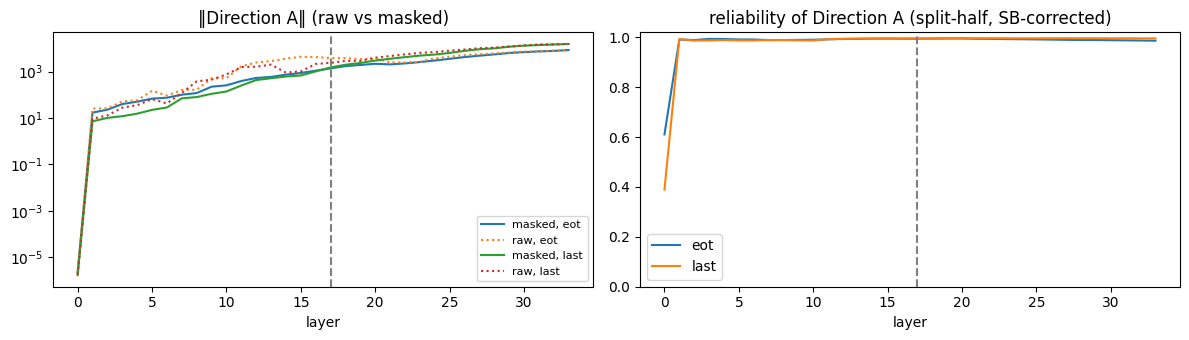

In [52]:
import matplotlib.pyplot as plt
g = torch.Generator().manual_seed(0)
Xh, Xs = R["tox_none"]["acts"], R["alp_none"]["acts"]           # [n, L, 2, d]
A_raw = Xh.mean(0) - Xs.mean(0)                                   # [L, 2, d]
A = masked(A_raw)
A_hat = unit(A)

NB = 50
W1h, W2h = half_W(len(Xh), NB, g); W1s, W2s = half_W(len(Xs), NB, g)
A1 = masked(wmean(Xh, W1h) - wmean(Xs, W1s)); A2 = masked(wmean(Xh, W2h) - wmean(Xs, W2s))
rel_A = spearman_brown(cosv(A1, A2).mean(0))                      # [L, 2]

cos_sel = float(cosv(A[L_STAR, 0], SEL["r"]))
record("direction_A_matches_causal_direction", cos_sel > 0.9, cos=round(cos_sel, 4),
       reliability_at_L_star=round(float(rel_A[L_STAR, 0]), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, pi in POSITIONS.items():
    ax[0].plot(A[:, pi].norm(dim=-1), label=f"masked, {name}")
    ax[0].plot(A_raw[:, pi].norm(dim=-1), ls=":", label=f"raw, {name}")
    ax[1].plot(rel_A[:, pi], label=name)
ax[0].set_yscale("log"); ax[0].set_title("‖Direction A‖ (raw vs masked)"); ax[0].legend(fontsize=8)
ax[1].set_title("reliability of Direction A (split-half, SB-corrected)"); ax[1].set_ylim(0, 1.02); ax[1].legend()
for a in ax:
    a.axvline(L_STAR, ls="--", c="grey"); a.set_xlabel("layer")
plt.tight_layout(); fig.savefig(f"{RUN}/reports/fig1_direction_A.png", dpi=130); plt.show()
save_res(direction_A={"cos_with_causal": cos_sel, "reliability": to_list(rel_A),
                      "norm_masked": to_list(A.norm(dim=-1), 2), "norm_raw": to_list(A_raw.norm(dim=-1), 2)})

## 6 · Category directions: one dial or many?

For each OR-Bench category *c* (excluding the catch-all "harmful"): C_c = mean(toxic-fit prompts in *c*) − mean(Alpaca-fit), masked.

- **Cosine matrix**, raw and **residue** (Direction A projected out of each C_c — what is category-specific).
- **Noise correction:** with \~25–45 prompts per category, part of any disagreement is sampling noise. We report corrected cosines cos / √(rel_i · rel_j) (values above 1 are clipped and indicate "indistinguishable within noise").
- **PCA:** share of variance of the unit category directions on PC1. **Null = "one dial + noise":** shuffle category labels among the toxic prompts (keeping sizes) — every shuffled "category" is then the global direction plus sampling noise. If the real PC1 share is **below** the null, categories have genuinely distinct dials.

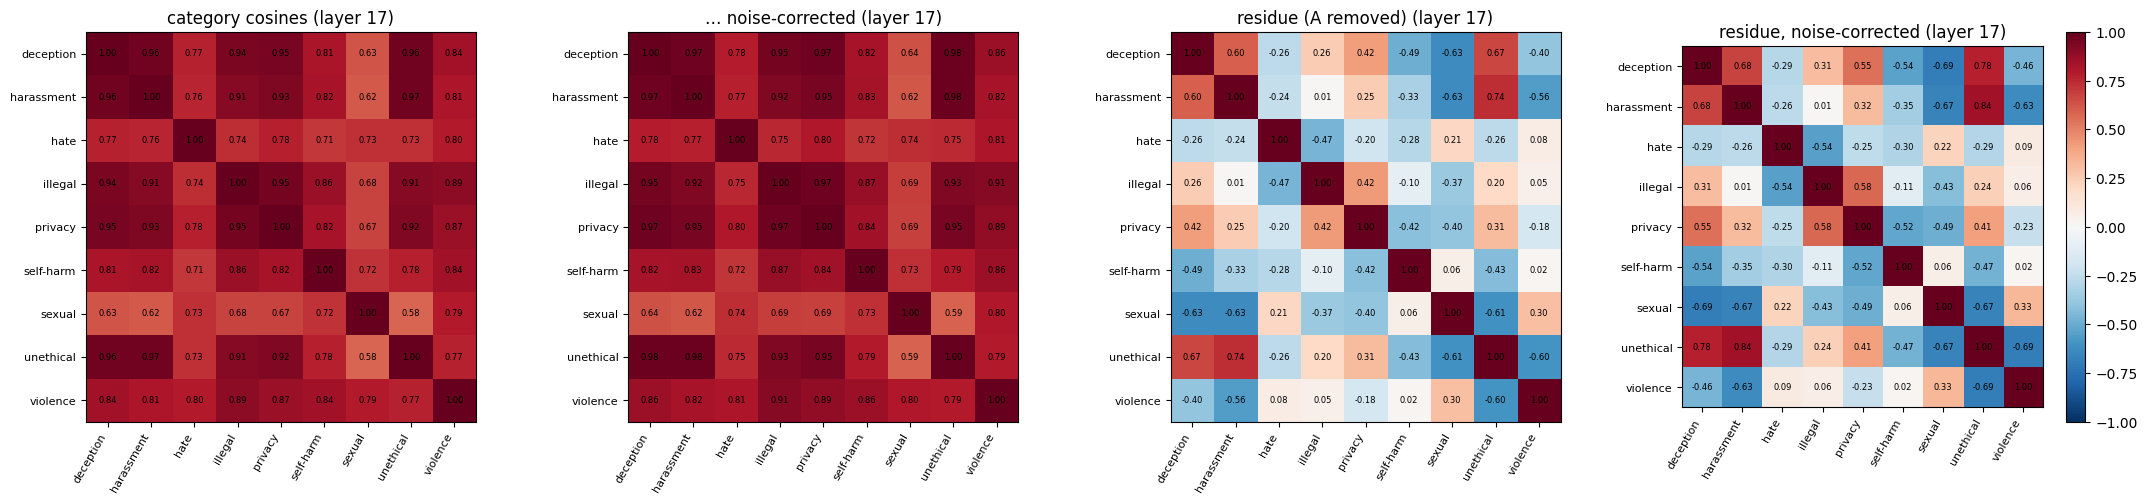

cos(category direction, Direction A): {'deception': np.float32(0.958), 'harassment': np.float32(0.951), 'hate': np.float32(0.845), 'illegal': np.float32(0.959), 'privacy': np.float32(0.958), 'self-harm': np.float32(0.91), 'sexual': np.float32(0.776), 'unethical': np.float32(0.929), 'violence': np.float32(0.924)}
category sizes: {'deception': 41, 'harassment': 38, 'hate': 29, 'illegal': 25, 'privacy': 30, 'self-harm': 46, 'sexual': 36, 'unethical': 30, 'violence': 35}
reliability (raw / residue): {'deception': (0.99, 0.86), 'harassment': (0.99, 0.91), 'hate': (0.98, 0.94), 'illegal': (0.98, 0.79), 'privacy': (0.97, 0.68), 'self-harm': (0.99, 0.95), 'sexual': (0.98, 0.96), 'unethical': (0.98, 0.86), 'violence': (0.98, 0.86)}


In [53]:
cat_all = tox_fit["category"].values
keep = ~np.isin(cat_all, EXCLUDE)
CATS = sorted(set(cat_all[keep]))
lab_k = cat_all[keep]
Xk = Xh[torch.from_numpy(keep)]                                   # toxic prompts used for categories
mu_s = Xs.mean(0)

def onehot_means(labels, X):
    M = torch.tensor(np.stack([(labels == c).astype(np.float32) for c in CATS]))
    M = M / M.sum(1, keepdim=True)
    return (M @ X.reshape(X.shape[0], -1)).reshape(len(CATS), *X.shape[1:])

C = masked(onehot_means(lab_k, Xk) - mu_s)                        # [K, L, 2, d]
C_res = C - (C * A_hat).sum(-1, keepdim=True) * A_hat             # remove the global component

# reliability of each category direction (split both the category's prompts and Alpaca)
rel_cat, rel_cat_res = [], []
for c in CATS:
    Xc = Xk[torch.from_numpy(lab_k == c)]
    W1c, W2c = half_W(len(Xc), NB, g); W1s, W2s = half_W(len(Xs), NB, g)
    c1 = masked(wmean(Xc, W1c) - wmean(Xs, W1s)); c2 = masked(wmean(Xc, W2c) - wmean(Xs, W2s))
    r1 = c1 - (c1 * A_hat).sum(-1, keepdim=True) * A_hat; r2 = c2 - (c2 * A_hat).sum(-1, keepdim=True) * A_hat
    rel_cat.append(spearman_brown(cosv(c1, c2).mean(0))); rel_cat_res.append(spearman_brown(cosv(r1, r2).mean(0)))
rel_cat, rel_cat_res = torch.stack(rel_cat), torch.stack(rel_cat_res)   # [K, L, 2]

def cos_matrix(V):                                                # V [K, d] -> [K, K]
    U = unit(V); return U @ U.T

def corrected(Mx, rel):
    denom = torch.sqrt(rel.clamp_min(1e-3)[:, None] * rel.clamp_min(1e-3)[None, :])
    return (Mx / denom).clamp(-1, 1)

pi = POSITIONS["eot"]
cm_raw = cos_matrix(C[:, L_STAR, pi]); cm_res = cos_matrix(C_res[:, L_STAR, pi])
cm_raw_c = corrected(cm_raw, rel_cat[:, L_STAR, pi]); cm_res_c = corrected(cm_res, rel_cat_res[:, L_STAR, pi])
cos_to_A = cosv(C[:, L_STAR, pi], A[L_STAR, pi])
offdiag = ~torch.eye(len(CATS), dtype=torch.bool)

fig, ax = plt.subplots(1, 4, figsize=(22, 5))
for a, Mx, t in zip(ax, [cm_raw, cm_raw_c, cm_res, cm_res_c],
                    ["category cosines", "… noise-corrected", "residue (A removed)", "residue, noise-corrected"]):
    im = a.imshow(Mx.numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
    a.set_xticks(range(len(CATS))); a.set_xticklabels(CATS, rotation=60, ha="right", fontsize=8)
    a.set_yticks(range(len(CATS))); a.set_yticklabels(CATS, fontsize=8); a.set_title(f"{t} (layer {L_STAR})")
    for i in range(len(CATS)):
        for j in range(len(CATS)):
            a.text(j, i, f"{Mx[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, ax=ax[-1]); plt.tight_layout()
fig.savefig(f"{RUN}/reports/fig2_category_cosines.png", dpi=130); plt.show()

print("cos(category direction, Direction A):", dict(zip(CATS, np.round(cos_to_A.numpy(), 3))))
print("category sizes:", {c: int((lab_k == c).sum()) for c in CATS})
print("reliability (raw / residue):", {c: (round(float(rel_cat[i, L_STAR, pi]), 2), round(float(rel_cat_res[i, L_STAR, pi]), 2))
                                      for i, c in enumerate(CATS)})
save_res(categories={"cats": CATS, "sizes": {c: int((lab_k == c).sum()) for c in CATS},
                     "cos_matrix_raw": to_list(cm_raw), "cos_matrix_raw_corrected": to_list(cm_raw_c),
                     "cos_matrix_residue": to_list(cm_res), "cos_matrix_residue_corrected": to_list(cm_res_c),
                     "cos_to_A": to_list(cos_to_A),
                     "mean_offdiag_raw": float(cm_raw[offdiag].mean()), "mean_offdiag_raw_corrected": float(cm_raw_c[offdiag].mean()),
                     "mean_offdiag_residue": float(cm_res[offdiag].mean()),
                     "mean_offdiag_residue_corrected": float(cm_res_c[offdiag].mean())})

null computed in 7s


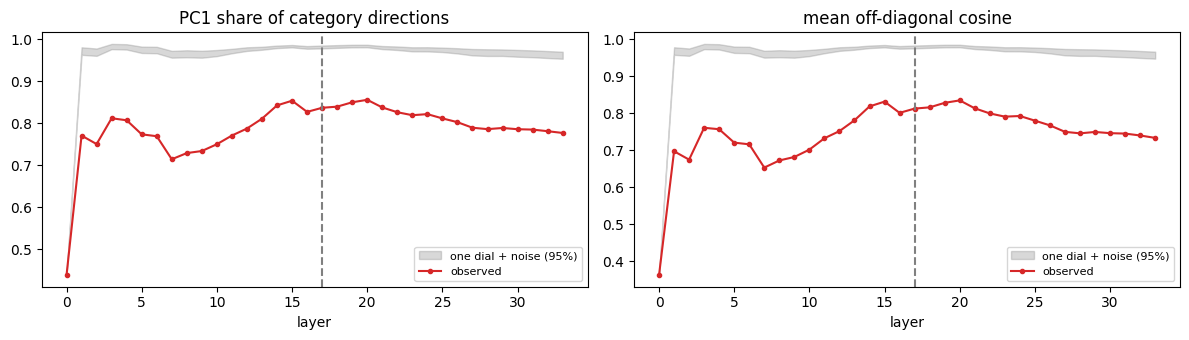

PASS pca_categories {"pc1_share_at_L_star": 0.837, "null_mean_at_L_star": 0.982, "p_value": 0.0, "mean_offdiag_cos": 0.812, "null_offdiag": 0.979}


In [54]:
# PCA of the unit category directions, every layer (eot), vs the "one dial + noise" null.
def pc1_share(V):                                   # V [K, L, d] -> [L]
    U = unit(V).permute(1, 0, 2)                    # [L, K, d]
    s = torch.linalg.svdvals(U)
    return (s[:, 0] ** 2) / (s ** 2).sum(-1)

Xk_eot = Xk[:, :, pi]                               # [n, L, d]
obs_pc1 = pc1_share(C[:, :, pi])
obs_off = torch.stack([cos_matrix(C[:, l, pi])[offdiag].mean() for l in range(N_LAYERS)])

N_PERM = 100
null_pc1, null_off = [], []
t0 = time.time()
for b in range(N_PERM):
    lab_p = lab_k[np.random.default_rng(b).permutation(len(lab_k))]
    Cp = masked(onehot_means(lab_p, Xk_eot) - mu_s[:, pi])
    null_pc1.append(pc1_share(Cp))
    null_off.append(torch.stack([cos_matrix(Cp[:, l])[offdiag].mean() for l in range(N_LAYERS)]))
null_pc1, null_off = torch.stack(null_pc1), torch.stack(null_off)     # [N_PERM, L]
p_pc1 = (null_pc1 <= obs_pc1).float().mean(0)                          # small p => more dimensions than one dial + noise
print(f"null computed in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, obs, null, t in [(ax[0], obs_pc1, null_pc1, "PC1 share of category directions"),
                        (ax[1], obs_off, null_off, "mean off-diagonal cosine")]:
    lo, hi = null.quantile(0.025, 0), null.quantile(0.975, 0)
    a.fill_between(range(N_LAYERS), lo, hi, alpha=0.3, color="grey", label="one dial + noise (95%)")
    a.plot(obs, c="tab:red", marker=".", label="observed")
    a.axvline(L_STAR, ls="--", c="grey"); a.set_xlabel("layer"); a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(f"{RUN}/reports/fig3_pca_null.png", dpi=130); plt.show()

record("pca_categories", True, pc1_share_at_L_star=round(float(obs_pc1[L_STAR]), 3),
       null_mean_at_L_star=round(float(null_pc1[:, L_STAR].mean()), 3), p_value=round(float(p_pc1[L_STAR]), 3),
       mean_offdiag_cos=round(float(obs_off[L_STAR]), 3), null_offdiag=round(float(null_off[:, L_STAR].mean()), 3))
save_res(pca={"pc1_share": to_list(obs_pc1), "null_mean": to_list(null_pc1.mean(0)),
              "null_lo": to_list(null_pc1.quantile(0.025, 0)), "null_hi": to_list(null_pc1.quantile(0.975, 0)),
              "p_value": to_list(p_pc1), "offdiag": to_list(obs_off), "null_offdiag": to_list(null_off.mean(0))})

## 7 · Headline: is the strict instruction's shift aligned with Direction A?

Shift = mean over the same Hard-1K prompts of (strict − neutral) activations — paired, so prompt content cancels.

- **Bootstrap 95% CI**: resample prompts (Hard-1K for the shift; toxic and Alpaca for A), 200×.
- **Noise ceiling** ≈ √(rel_A · rel_shift): the best cosine achievable given sampling noise in both vectors.
- **Floor (random-contrast)**: |cos| between A and the difference of two *random halves* of the benign Hard-1K prompts (same condition), 200× → 95th percentile. This is how aligned A is with an arbitrary content difference in Gemma's anisotropic activation space — the cosine you would see by chance. (A sign-flip permutation is *not* a valid floor for a cosine: flipping the signs of consistent per-prompt shifts changes the mean's magnitude, not its direction.)
- **Exchange rate**: (shift · Â) / ‖A‖ — the fraction of the full harmful-vs-harmless gap the instruction moves benign prompts along the refusal axis.

Also shown: strict − none and neutral − none.

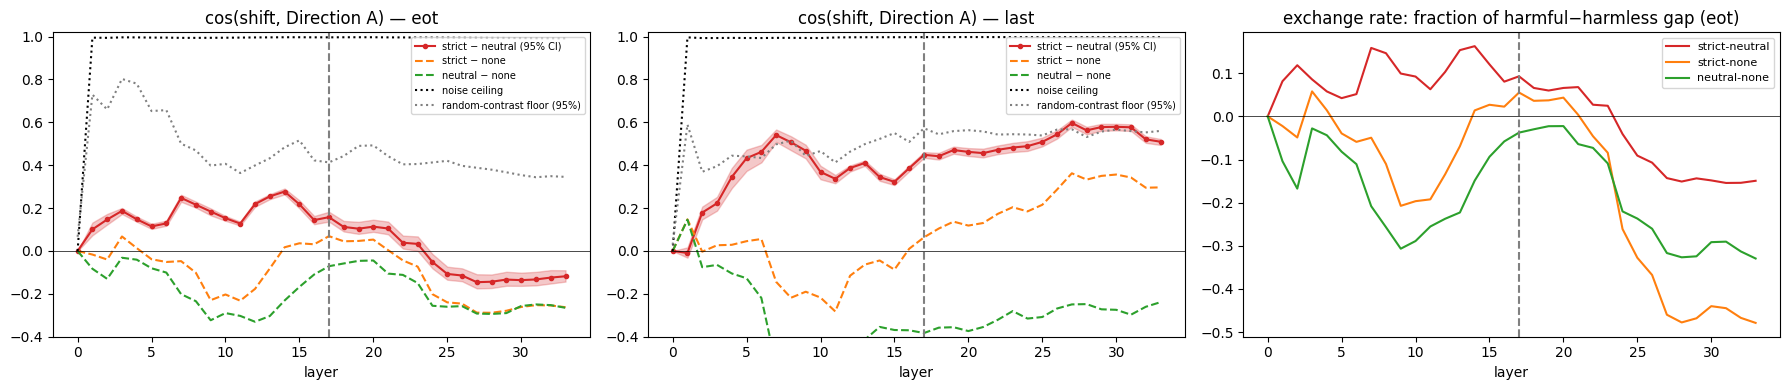

PASS headline_shift_vs_A {"layer": 17, "cos": 0.1578, "ci": [0.1371, 0.1829], "ceiling": 0.9967, "floor": 0.4133, "cos_with_causal_direction": 0.1521, "exchange_rate": 0.0929, "peak_layer": 14, "peak_cos": 0.2772}


In [55]:
D = {"strict-neutral": R["hard_strict"]["acts"] - R["hard_neutral"]["acts"],
     "strict-none": R["hard_strict"]["acts"] - R["hard_none"]["acts"],
     "neutral-none": R["hard_neutral"]["acts"] - R["hard_none"]["acts"]}
n = len(hard_fit)
shift = {k: masked(v.mean(0)) for k, v in D.items()}               # [L, 2, d]
cos_shift = {k: cosv(v, A) for k, v in shift.items()}              # [L, 2]
rate = {k: (v * A_hat).sum(-1) / A.norm(dim=-1) for k, v in shift.items()}

# reliability of the main shift
W1, W2 = half_W(n, NB, g)
Dm = D["strict-neutral"]
rel_shift = spearman_brown(cosv(masked(wmean(Dm, W1)), masked(wmean(Dm, W2))).mean(0))
ceiling = torch.sqrt(rel_A.clamp_min(0) * rel_shift.clamp_min(0))

# bootstrap CI and random-contrast floor (batched to keep memory small)
Hn = R["hard_none"]["acts"]
boots, nulls = [], []
for _ in range(4):
    Wd, Wh_, Ws_ = boot_W(n, 50, g), boot_W(len(Xh), 50, g), boot_W(len(Xs), 50, g)
    boots.append(cosv(masked(wmean(Dm, Wd)), masked(wmean(Xh, Wh_) - wmean(Xs, Ws_))))
    H1, H2 = half_W(n, 50, g)
    nulls.append(cosv(masked(wmean(Hn, H1) - wmean(Hn, H2)), A[None]).abs())
boots, nulls = torch.cat(boots), torch.cat(nulls)                  # [200, L, 2]
ci_lo, ci_hi = boots.quantile(0.025, 0), boots.quantile(0.975, 0)
floor = nulls.quantile(0.95, 0)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (pname, pidx) in zip(ax[:2], POSITIONS.items()):
    a.fill_between(range(N_LAYERS), ci_lo[:, pidx], ci_hi[:, pidx], alpha=0.25, color="tab:red")
    a.plot(cos_shift["strict-neutral"][:, pidx], c="tab:red", marker=".", label="strict − neutral (95% CI)")
    a.plot(cos_shift["strict-none"][:, pidx], c="tab:orange", ls="--", label="strict − none")
    a.plot(cos_shift["neutral-none"][:, pidx], c="tab:green", ls="--", label="neutral − none")
    a.plot(ceiling[:, pidx], c="k", ls=":", label="noise ceiling")
    a.plot(floor[:, pidx], c="grey", ls=":", label="random-contrast floor (95%)")
    a.axvline(L_STAR, ls="--", c="grey"); a.axhline(0, c="k", lw=0.5)
    a.set_ylim(-0.4, 1.02); a.set_xlabel("layer"); a.set_title(f"cos(shift, Direction A) — {pname}"); a.legend(fontsize=7)
for k, c_ in [("strict-neutral", "tab:red"), ("strict-none", "tab:orange"), ("neutral-none", "tab:green")]:
    ax[2].plot(rate[k][:, 0], c=c_, label=k)
ax[2].axvline(L_STAR, ls="--", c="grey"); ax[2].axhline(0, c="k", lw=0.5)
ax[2].set_title("exchange rate: fraction of harmful−harmless gap (eot)"); ax[2].set_xlabel("layer"); ax[2].legend(fontsize=8)
plt.tight_layout(); fig.savefig(f"{RUN}/reports/fig4_headline_shift.png", dpi=130); plt.show()

e = POSITIONS["eot"]
head = {"cos": round(float(cos_shift["strict-neutral"][L_STAR, e]), 4),
        "ci": [round(float(ci_lo[L_STAR, e]), 4), round(float(ci_hi[L_STAR, e]), 4)],
        "ceiling": round(float(ceiling[L_STAR, e]), 4), "floor": round(float(floor[L_STAR, e]), 4),
        "cos_with_causal_direction": round(float(cosv(shift["strict-neutral"][L_STAR, e], SEL["r"])), 4),
        "exchange_rate": round(float(rate["strict-neutral"][L_STAR, e]), 4),
        "peak_layer": int(cos_shift["strict-neutral"][:, e].argmax()),
        "peak_cos": round(float(cos_shift["strict-neutral"][:, e].max()), 4)}
record("headline_shift_vs_A", True, layer=L_STAR, **head)
save_res(headline=head, shift_curves={k: to_list(v) for k, v in cos_shift.items()},
         exchange_rate={k: to_list(v) for k, v in rate.items()},
         ci_lo=to_list(ci_lo), ci_hi=to_list(ci_hi), ceiling=to_list(ceiling), floor=to_list(floor),
         rel_shift=to_list(rel_shift))

## 8 · Does the instruction push each category toward its *own* dial?

For each Hard-1K category: the strict − neutral shift of **its** benign prompts, compared with every toxic category direction (residues, so the shared global component is removed). If the diagonal (privacy-shift vs privacy-dial, …) beats the off-diagonal, the instruction engages **category-specific** dials, not only one global dial. Significance: permute the column labels 2,000×.

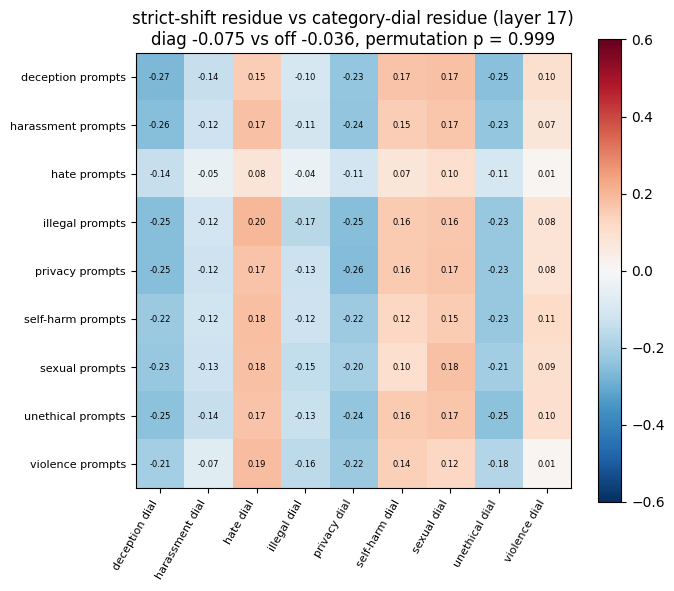

PASS category_specific_shift {"diag": -0.0754, "offdiag": -0.0362, "p": 0.999, "cats": ["deception", "harassment", "hate", "illegal", "privacy", "self-harm", "sexual", "unethical", "violence"], "n_per_cat": {"deception": 36, "harassment": 20, "hate": 27, "illegal": 263, "privacy": 99, "self-harm": 31, "sexual": 33, "unethical": 62, "violence": 33}}


In [56]:
hard_cat = hard_fit["category"].values
CATS_H = [c for c in CATS if (hard_cat == c).sum() >= 15]
Dm_e = Dm[:, L_STAR, e]
sh_c = torch.stack([masked(Dm_e[torch.from_numpy(hard_cat == c)].mean(0)) for c in CATS_H])     # [Kh, d]
Ah = A_hat[L_STAR, e]
sh_res = sh_c - (sh_c @ Ah)[:, None] * Ah
dial_res = C_res[[CATS.index(c) for c in CATS_H], L_STAR, e]
Mx = unit(sh_res) @ unit(dial_res).T                                  # rows: Hard shift by category; cols: toxic dial

diag = Mx.diag().mean(); off = Mx[~torch.eye(len(CATS_H), dtype=torch.bool)].mean()
rng = np.random.default_rng(0)
null = []
for _ in range(2000):
    p = torch.from_numpy(rng.permutation(len(CATS_H)))
    Mp = Mx[:, p]
    null.append(float(Mp.diag().mean() - Mp[~torch.eye(len(CATS_H), dtype=torch.bool)].mean()))
p_diag = float((np.array(null) >= float(diag - off)).mean())

fig, a = plt.subplots(figsize=(7, 6))
im = a.imshow(Mx.numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6)
a.set_xticks(range(len(CATS_H))); a.set_xticklabels([f"{c} dial" for c in CATS_H], rotation=60, ha="right", fontsize=8)
a.set_yticks(range(len(CATS_H))); a.set_yticklabels([f"{c} prompts" for c in CATS_H], fontsize=8)
for i in range(len(CATS_H)):
    for j in range(len(CATS_H)):
        a.text(j, i, f"{Mx[i, j]:.2f}", ha="center", va="center", fontsize=6)
a.set_title(f"strict-shift residue vs category-dial residue (layer {L_STAR})\n"
            f"diag {diag:.3f} vs off {off:.3f}, permutation p = {p_diag:.3f}")
plt.colorbar(im); plt.tight_layout(); fig.savefig(f"{RUN}/reports/fig5_category_specific_shift.png", dpi=130); plt.show()
record("category_specific_shift", True, diag=round(float(diag), 4), offdiag=round(float(off), 4), p=p_diag,
       cats=CATS_H, n_per_cat={c: int((hard_cat == c).sum()) for c in CATS_H})
save_res(category_shift={"cats": CATS_H, "matrix": to_list(Mx), "diag": float(diag), "offdiag": float(off), "p": p_diag})

## 9 · Projections on the refusal axis (caution-map preview)

Each prompt's activation at the causal layer projected onto the causal direction r̂ (from 01). If the strict instruction moves benign prompts toward the harmful cluster, the Hard-1K histograms slide right under *strict*. Dot colour on the page later = whether the reply starts as a refusal (fast score > 0).

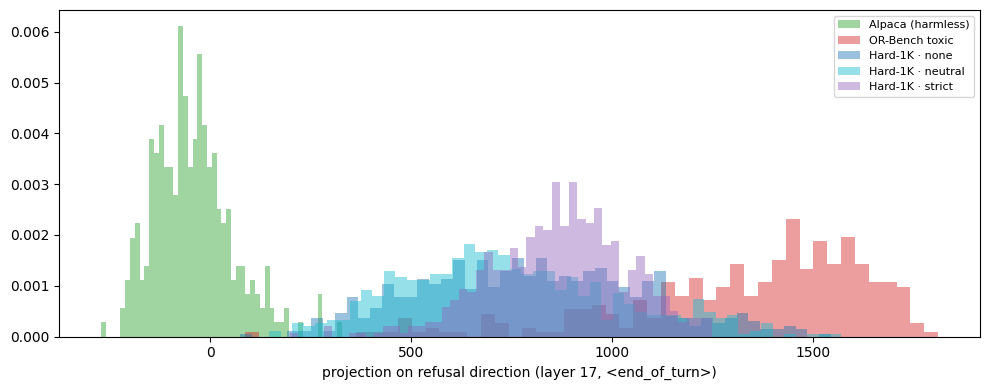

share of Hard-1K prompts past the harmful/harmless midpoint: {'hard_none': 0.688, 'hard_neutral': 0.615, 'hard_strict': 0.904}
share whose reply starts as a refusal (fast score > 0):     {'hard_none': 0.111, 'hard_neutral': 0.073, 'hard_strict': 0.674}


In [57]:
r_hat = unit(SEL["r"].float())
def proj(run):
    return (masked(run["acts"][:, L_STAR, e]) @ r_hat)

groups = [("Alpaca (harmless)", "alp_none", "tab:green"), ("OR-Bench toxic", "tox_none", "tab:red"),
          ("Hard-1K · none", "hard_none", "tab:blue"), ("Hard-1K · neutral", "hard_neutral", "tab:cyan"),
          ("Hard-1K · strict", "hard_strict", "tab:purple")]
fig, a = plt.subplots(figsize=(10, 4))
page = {}
for label, key, c_ in groups:
    v = proj(R[key]).numpy()
    a.hist(v, bins=50, alpha=0.45, color=c_, label=label, density=True)
    page[key] = {"ids": R[key]["ids"], "proj": np.round(v, 2).tolist(),
                 "refusal_score": np.round(R[key]["refusal_score"].numpy(), 2).tolist()}
a.set_xlabel(f"projection on refusal direction (layer {L_STAR}, <end_of_turn>)"); a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(f"{RUN}/reports/fig6_projections.png", dpi=130); plt.show()
save_json(page, f"{RUN}/page/projections.json")

mid = 0.5 * (float(proj(R["alp_none"]).mean()) + float(proj(R["tox_none"]).mean()))
frac = {k: round(float((proj(R[k]) > mid).float().mean()), 3) for k in ["hard_none", "hard_neutral", "hard_strict"]}
fast = {k: round(float((R[k]["refusal_score"] > 0).float().mean()), 3) for k in ["hard_none", "hard_neutral", "hard_strict"]}
print("share of Hard-1K prompts past the harmful/harmless midpoint:", frac)
print("share whose reply starts as a refusal (fast score > 0):    ", fast)
save_res(projection={"midpoint": mid, "past_midpoint": frac, "fast_refusal": fast})

## 10 · Sensitivity to the mask, and summary

In [58]:
sens = {}
for mname in MASKS:
    A_m = masked(A_raw, mname)[L_STAR, e]
    sh_m = masked(Dm.mean(0), mname)[L_STAR, e]
    C_m = masked(onehot_means(lab_k, Xk) - mu_s, mname)[:, L_STAR, e]
    sens[mname] = {"n_dims_masked": len(MASKS[mname]),
                   "cos_shift_A": round(float(cosv(sh_m, A_m)), 4),
                   "pc1_share": round(float(pc1_share(C_m[:, None])[0]), 4),
                   "mean_offdiag_cos": round(float(cos_matrix(C_m)[offdiag].mean()), 4)}
print(pd.DataFrame(sens).T.to_string())
save_res(mask_sensitivity=sens)

print("\n=== Headline numbers (layer", L_STAR, ", <end_of_turn>) ===")
print(f"cos(strict−neutral shift, Direction A) = {head['cos']:.3f}  95% CI {head['ci']}  "
      f"ceiling {head['ceiling']:.3f}  floor {head['floor']:.3f}")
print(f"cos(shift, causal direction)            = {head['cos_with_causal_direction']:.3f}")
print(f"exchange rate                           = {head['exchange_rate']:.3f} of the harmful−harmless gap")
print(f"category PC1 share                      = {float(obs_pc1[L_STAR]):.3f}  (one-dial null {float(null_pc1[:, L_STAR].mean()):.3f}, p = {float(p_pc1[L_STAR]):.3f})")
print(f"category-specific shift                 = diag {float(diag):.3f} vs off {float(off):.3f}, p = {p_diag:.3f}")
for k, v in CHECKS.items():
    print(f"{k:40s} {'PASS' if v['ok'] else 'FAIL'}")
print("\nSaved under:", RUN)
if IN_KAGGLE:
    print("Kaggle: Save Version (or zip /kaggle/working/IE624, skipping acts/) before the session ends.")

       n_dims_masked  cos_shift_A  pc1_share  mean_offdiag_cos
raw              0.0      -0.2023     0.9725            0.9689
small           15.0       0.1778     0.8404            0.8166
large           46.0       0.1578     0.8368            0.8124

=== Headline numbers (layer 17 , <end_of_turn>) ===
cos(strict−neutral shift, Direction A) = 0.158  95% CI [0.1371, 0.1829]  ceiling 0.997  floor 0.413
cos(shift, causal direction)            = 0.152
exchange rate                           = 0.093 of the harmful−harmless gap
category PC1 share                      = 0.837  (one-dial null 0.982, p = 0.000)
category-specific shift                 = diag -0.075 vs off -0.036, p = 0.999
model_load                               PASS
cache                                    PASS
direction_A_matches_causal_direction     PASS
pca_categories                           PASS
headline_shift_vs_A                      PASS
category_specific_shift                  PASS

Saved under: /kaggle/working/IE62

### Reading the results

| Observation | Meaning |
| --- | --- |
| Headline cosine near the ceiling | The instruction moves benign prompts along the trained refusal axis — **one dial** |
| Headline cosine well above the floor but well below the ceiling | **Partially shared**: part of the instruction's effect is on the refusal axis, part elsewhere |
| Headline cosine within the floor | The instruction's effect is **orthogonal** to the trained axis |
| PC1 share below the one-dial null (small p) | Harm categories have **genuinely distinct dials** |
| Diagonal > off-diagonal in §8 (small p) | The instruction pushes each category toward **its own** dial |

Large raw-vs-masked differences in §10 are themselves a finding: without masking, cosines mostly measure Gemma's massive dimensions.